In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

## y = 3x + 5 + noise

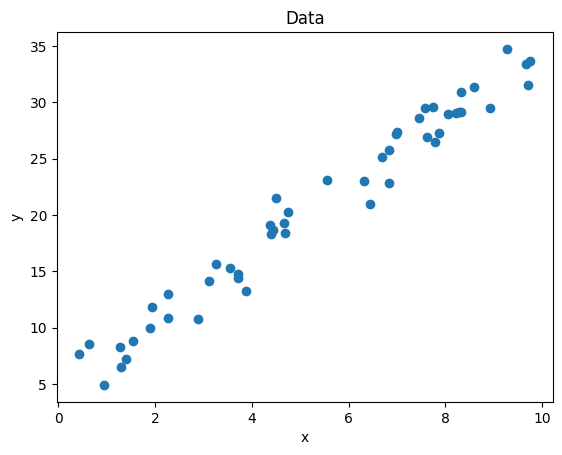

In [3]:
rng = np.random.default_rng(42) # random numbers with seed equals 42
n = 50
X = rng.uniform(0, 10, size=(n, 1))
y = 3 * X.ravel() + 5 + rng.normal(0, 2, size=n) ## noise make realistic
plt.scatter(X, y)
plt.xlabel("x"); plt.ylabel("y"); plt.title("Data")
plt.show()

In [3]:
model = LinearRegression()
model.fit(X, y)
y_pred = model.predict(X)
print("slope :", model.coef_[0])
print("intercept:", model.intercept_)

slope : 3.024152021533245
intercept: 4.537317866572625


In [4]:
def sse(y, y_pred):
  # SSE = sum of (y - y_hat)^2
  return np.sum((y - y_pred) ** 2)

def rmse(y, y_pred):
  # RMSE = sqrt((1/n) * sum of (y - y_hat)^2)
  n = len(y)
  return np.sqrt((1/n) * np.sum((y - y_pred) ** 2))

def ss_total(y):
  # SS_total = sum of (y - y_mean) ^ 2
  return np.sum((y - np.mean(y)) ** 2)

def r2(y, y_pred):
  # R^2 = 1 - SSE / SS_total
  return 1 - sse(y, y_pred) / ss_total(y)


print(f"SSE =  {sse(y, y_pred):.4f}")
print(f"RMSE =  {rmse(y, y_pred):.4f}")
print(f"SS_total = {ss_total(y):.4f}")
print(f"R^2 = {r2(y, y_pred):.4f}")

SSE =  114.6958
RMSE =  1.5146
SS_total = 3644.5874
R^2 = 0.9685


In [5]:
print("RSME mine", rmse(y, y_pred), "| sklearn:", np.sqrt(mean_squared_error(y, y_pred)))
print("R^2 mine:", r2(y, y_pred), "| sklearn:", r2_score(y, y_pred))

assert np.isclose(rmse(y, y_pred), np.sqrt(mean_squared_error(y, y_pred)))
assert np.isclose(r2(y, y_pred), r2_score(y, y_pred))
print("Both match")

RSME mine 1.5145679640997403 | sklearn: 1.5145679640997403
R^2 mine: 0.9685298244713475 | sklearn: 0.9685298244713475
Both match


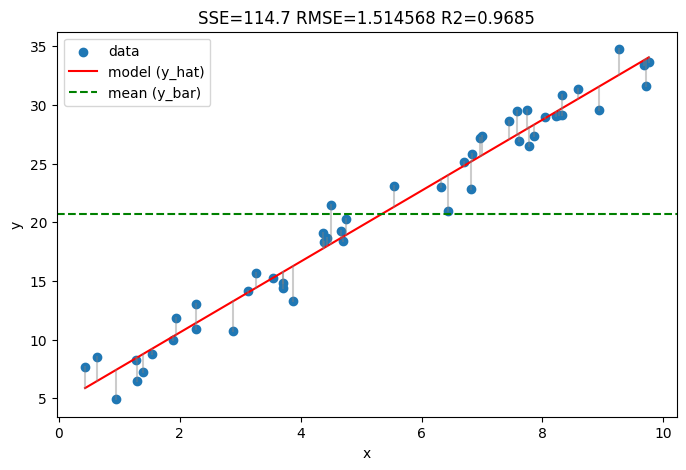

In [6]:
from matplotlib.lines import lineStyles
order = np.argsort(X.ravel())
plt.figure(figsize=(8, 5))
plt.scatter(X, y, label = "data")
plt.plot(X[order], y_pred[order], color="red", label="model (y_hat)")
plt.axhline(np.mean(y), color="green", linestyle="--", label="mean (y_bar)")
for xi, yi, pi in zip(X.ravel(), y, y_pred):
  plt.plot([xi, xi], [yi, pi], color="gray", alpha=0.4)

plt.legend(); plt.xlabel("x"); plt.ylabel("y")
plt.title(f"SSE={sse(y, y_pred):.1f} RMSE={rmse(y, y_pred):2f} R2={r2(y, y_pred):.4f}")
plt.show()

